### 1. Import Libraries and Download NLTK Data
Importing the necessary libraries for data manipulation, visualization, text processing, and machine learning.

In [5]:
!pip install nltk


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\bayan\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import numpy as np

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

True

### 2. Load Dataset and Plot Class Balance
Loading the financial sentiment dataset and visualizing the distribution of positive, negative, and neutral classes.

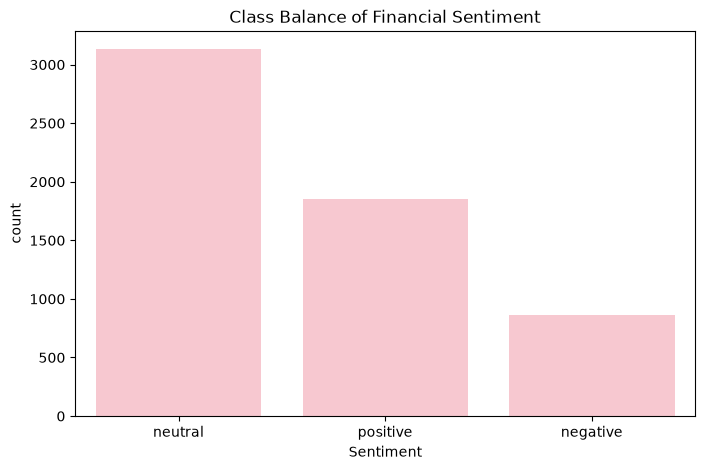

In [6]:
df = pd.read_csv('data.csv')

plt.figure(figsize=(8, 5))
sns.countplot(data=df, color='pink', x='Sentiment', order=df['Sentiment'].value_counts().index)
plt.title('Class Balance of Financial Sentiment')
plt.show()

### 3. Define Text Cleaning Function
Creating a function to clean the text by converting to lowercase, and removing stock tickers, numbers, punctuation, and extra spaces. It also removes stopwords and applies lemmatization.

In [7]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'\$\w+', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return ' '.join(tokens)

### 4. Apply Text Cleaning and Show Examples
Applying the cleaning function to the dataset and displaying 3 examples before and after cleaning to verify the results.

In [8]:
examples_before = df['Sentence'].head(3).tolist()

df['clean_text'] = df['Sentence'].apply(clean_text)

examples_after = df['clean_text'].head(3).tolist()

print("--- 3 Sentences Before Cleaning ---")
for i, ex in enumerate(examples_before): 
    print(f"{i+1}: {ex}")
    
print("\n--- 3 Sentences After Cleaning ---")
for i, ex in enumerate(examples_after): 
    print(f"{i+1}: {ex}")

--- 3 Sentences Before Cleaning ---
1: The GeoSolutions technology will leverage Benefon 's GPS solutions by providing Location Based Search Technology , a Communities Platform , location relevant multimedia content and a new and powerful commercial model .
2: $ESI on lows, down $1.50 to $2.50 BK a real possibility
3: For the last quarter of 2010 , Componenta 's net sales doubled to EUR131m from EUR76m for the same period a year earlier , while it moved to a zero pre-tax profit from a pre-tax loss of EUR7m .

--- 3 Sentences After Cleaning ---
1: geosolutions technology leverage benefon gps solution providing location based search technology community platform location relevant multimedia content new powerful commercial model
2: low bk real possibility
3: last quarter componenta net sale doubled eurm eurm period year earlier moved zero pretax profit pretax loss eurm


### 5. Stratified Train/Test Split
Splitting the data into training (80%) and testing (20%) sets. Using stratified split to maintain the same class balance in both sets.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['Sentiment'], 
    test_size=0.2, 
    stratify=df['Sentiment'], 
    random_state=42
)

### 6. Text Vectorization using TF-IDF
Converting the cleaned text into numerical vectors using `TfidfVectorizer`. The vectorizer is fitted on the training set only to prevent data leakage.

In [10]:
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

### 7. Train Logistic Regression Model
Training a Logistic Regression classifier on the vectorized training data.

In [11]:
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_vec, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

### 8. Model Evaluation and Confusion Matrix
Predicting the sentiment for the test set and evaluating the model using Accuracy and F1 Score. Plotting a confusion matrix heatmap to visualize the performance across all classes.

Accuracy: 0.6878
F1 Score: 0.6585


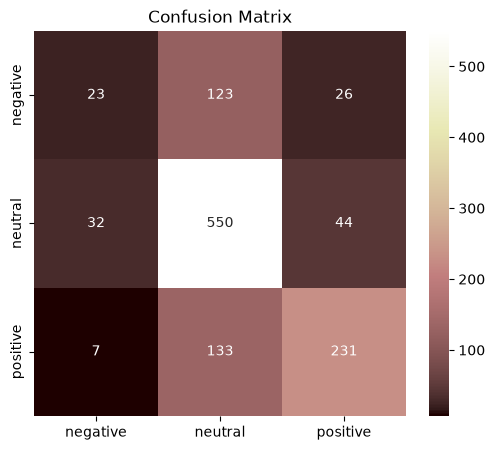

In [17]:
y_pred = clf.predict(X_test_vec)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='pink', 
            xticklabels=clf.classes_, yticklabels=clf.classes_)
plt.title('Confusion Matrix')
plt.show()

### 9. Top 10 Positive and Negative Words
Extracting and printing the 10 words with the highest positive weights and the 10 words with the highest negative weights from the Logistic Regression model.

In [18]:
feature_names = np.array(vectorizer.get_feature_names_out())

pos_class_idx = list(clf.classes_).index('positive')
neg_class_idx = list(clf.classes_).index('negative')

top10_pos_idx = clf.coef_[pos_class_idx].argsort()[-10:][::-1]
top10_pos_words = feature_names[top10_pos_idx]

top10_neg_idx = clf.coef_[neg_class_idx].argsort()[-10:][::-1]
top10_neg_words = feature_names[top10_neg_idx]

print("--- Top 10 Words with Most Positive Weights ---")
for word in top10_pos_words: 
    print(word)
    
print("\n--- Top 10 Words with Most Negative Weights ---")
for word in top10_neg_words: 
    print(word)

--- Top 10 Words with Most Positive Weights ---
rose
increase
increased
buy
grew
positive
signed
long
awarded
improved

--- Top 10 Words with Most Negative Weights ---
decreased
lower
fall
short
fell
cut
recall
weak
hit
bearish


### Conclusion: Do the feature weights make sense?
Yes, they make perfect sense for financial context. Positive weights include words like "rose", "increase", and "improved", which naturally indicate financial growth. Conversely, negative weights include words like "decreased", "fell", and "lower", which clearly represent market decline or financial loss.